
# Skin Cancer Detection Using Deep Learning

## Project Overview
This project explores multi-class classification of skin lesion images using deep learning and transfer learning.

## Objectives
- Load and explore the HAM10000 dataset.
- Analyze image labels and class distribution.
- Preprocess images for model training.
- Train a MobileNetV2-based image classifier.
- Evaluate performance using accuracy, precision, recall, F1-score, and a confusion matrix.
- Document the workflow and results for GitHub.

## Dataset
Skin Cancer MNIST: HAM10000  
Kaggle: https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000

## Technology Stack
- Python
- TensorFlow / Keras
- NumPy and Pandas
- Matplotlib and Seaborn
- Scikit-learn
- Google Colab

## Important Disclaimer
This is an educational machine-learning project, not a medical diagnostic tool. Its predictions must not be used to diagnose skin cancer or make treatment decisions.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# Install KaggleHub
!pip -q install kagglehub

import kagglehub
import os

# Download dataset through KaggleHub
path = kagglehub.dataset_download(
    "kmader/skin-cancer-mnist-ham10000"
)

print("Path to dataset files:", path)

# List files and folders
for root, dirs, files in os.walk(path):
    level = root.replace(path, "").count(os.sep)

    if level <= 2:
        print(
            "  " * level,
            os.path.basename(root) or root,
            f"({len(files)} files)"
        )

Using Colab cache for faster access to the 'skin-cancer-mnist-ham10000' dataset.
Path to dataset files: /kaggle/input/skin-cancer-mnist-ham10000
 skin-cancer-mnist-ham10000 (5 files)
   HAM10000_images_part_1 (5000 files)
   ham10000_images_part_1 (5000 files)
   HAM10000_images_part_2 (5015 files)
   ham10000_images_part_2 (5015 files)


In [3]:
# Find all CSV files
csv_files = []

for root, dirs, files in os.walk(path):
    for file in files:
        if file.lower().endswith(".csv"):
            csv_files.append(os.path.join(root, file))

print("CSV files found:", len(csv_files))

for file in csv_files:
    print(file)

CSV files found: 5
/kaggle/input/skin-cancer-mnist-ham10000/hmnist_8_8_RGB.csv
/kaggle/input/skin-cancer-mnist-ham10000/hmnist_28_28_RGB.csv
/kaggle/input/skin-cancer-mnist-ham10000/hmnist_8_8_L.csv
/kaggle/input/skin-cancer-mnist-ham10000/hmnist_28_28_L.csv
/kaggle/input/skin-cancer-mnist-ham10000/HAM10000_metadata.csv


In [4]:
metadata_path = next(
    file for file in csv_files
    if os.path.basename(file).lower() == "ham10000_metadata.csv"
)

df = pd.read_csv(metadata_path)

print("Dataset shape:", df.shape)
display(df.head())
print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (10015, 7)


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear



Columns:
['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']


In [5]:
print("Total metadata rows:", len(df))
print("\nClass distribution:")
display(df["dx"].value_counts().to_frame("image_count"))

# Find image files
image_extensions = (".jpg", ".jpeg", ".png")
image_paths = {}

for root, dirs, files in os.walk(path):
    for file in files:
        if file.lower().endswith(image_extensions):
            image_paths[file] = os.path.join(root, file)

print("\nTotal image files found:", len(image_paths))

df["image_path"] = df["image_id"].map(
    lambda image_id: image_paths.get(image_id + ".jpg")
)

print("Images matched to metadata:", df["image_path"].notna().sum())
display(df[["image_id", "dx", "image_path"]].head())

Total metadata rows: 10015

Class distribution:


,image_count
dx,
nv,6705
mel,1113
bkl,1099
bcc,514
akiec,327
vasc,142
df,115



Total image files found: 10015
Images matched to metadata: 10015


,image_id,dx,image_path
0,ISIC_0027419,bkl,/kaggle/input/skin-cancer-mnist-ham10000/ham10...
1,ISIC_0025030,bkl,/kaggle/input/skin-cancer-mnist-ham10000/ham10...
2,ISIC_0026769,bkl,/kaggle/input/skin-cancer-mnist-ham10000/ham10...
3,ISIC_0025661,bkl,/kaggle/input/skin-cancer-mnist-ham10000/ham10...
4,ISIC_0031633,bkl,/kaggle/input/skin-cancer-mnist-ham10000/ham10...



## 1. Dataset Overview

The HAM10000 dataset contains dermatoscopic images of skin lesions and corresponding metadata.

In this section, we inspect the dataset structure, identify the available lesion categories, and examine the number of images in each category.

Understanding class distribution helps identify class imbalance, which can affect model training and evaluation.

**Dataset source:** [Skin Cancer MNIST: HAM10000](https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000)


In [6]:
# Display dataset dimensions
print("Number of records:", len(df))
print("Number of columns:", len(df.columns))

# Display class distribution
class_counts = df["dx"].value_counts().sort_index()

print("\nImages per class:")
display(class_counts.to_frame(name="Image Count"))

Number of records: 10015
Number of columns: 8

Images per class:


,Image Count
dx,
akiec,327
bcc,514
bkl,1099
df,115
mel,1113
nv,6705
vasc,142



### 1.1 Class Distribution Visualization

The following bar chart shows the number of images available for each skin lesion category.

This visualization helps us understand whether the dataset is balanced or whether some categories contain substantially more images than others.


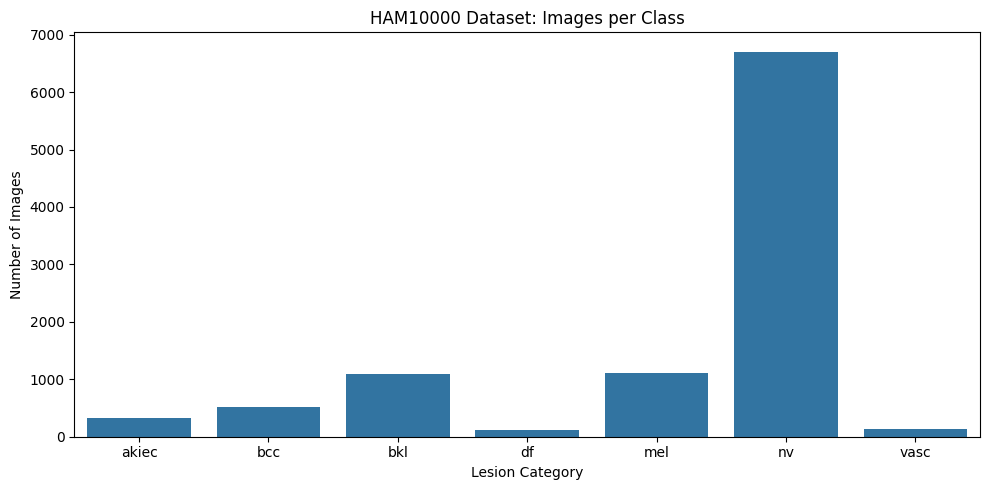

In [7]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("HAM10000 Dataset: Images per Class")
plt.xlabel("Lesion Category")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()


## 2. Understanding the Target Classes

The HAM10000 dataset contains seven diagnostic categories:

| Label | Category | Description |
|---|---|---|
| akiec | Actinic keratoses and intraepithelial carcinoma | Lesions associated with abnormal skin cell changes |
| bcc | Basal cell carcinoma | A type of skin cancer |
| bkl | Benign keratosis-like lesions | A group of generally benign lesions |
| df | Dermatofibroma | A generally benign skin lesion |
| mel | Melanoma | A potentially serious form of skin cancer |
| nv | Melanocytic nevi | Commonly known as moles |
| vasc | Vascular lesions | Lesions involving blood vessels |

The target variable is `dx`. This project performs seven-class image classification rather than binary classification.

**Important:** These labels are provided for educational model development. Model predictions are not medical diagnoses.


In [8]:
print("Missing values in each column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate metadata rows:", df.duplicated().sum())

print("\nUnique lesion categories:")
print(sorted(df["dx"].dropna().unique()))

Missing values in each column:


,Missing Values
lesion_id,0
image_id,0
dx,0
dx_type,0
age,57
sex,0
localization,0
image_path,0



Duplicate metadata rows: 0

Unique lesion categories:
['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']



## 3. Exploratory Image Analysis

In this section, we display sample dermatoscopic images alongside their corresponding lesion labels.

Visual inspection helps us understand image characteristics and verify that image files have been matched correctly with the metadata.


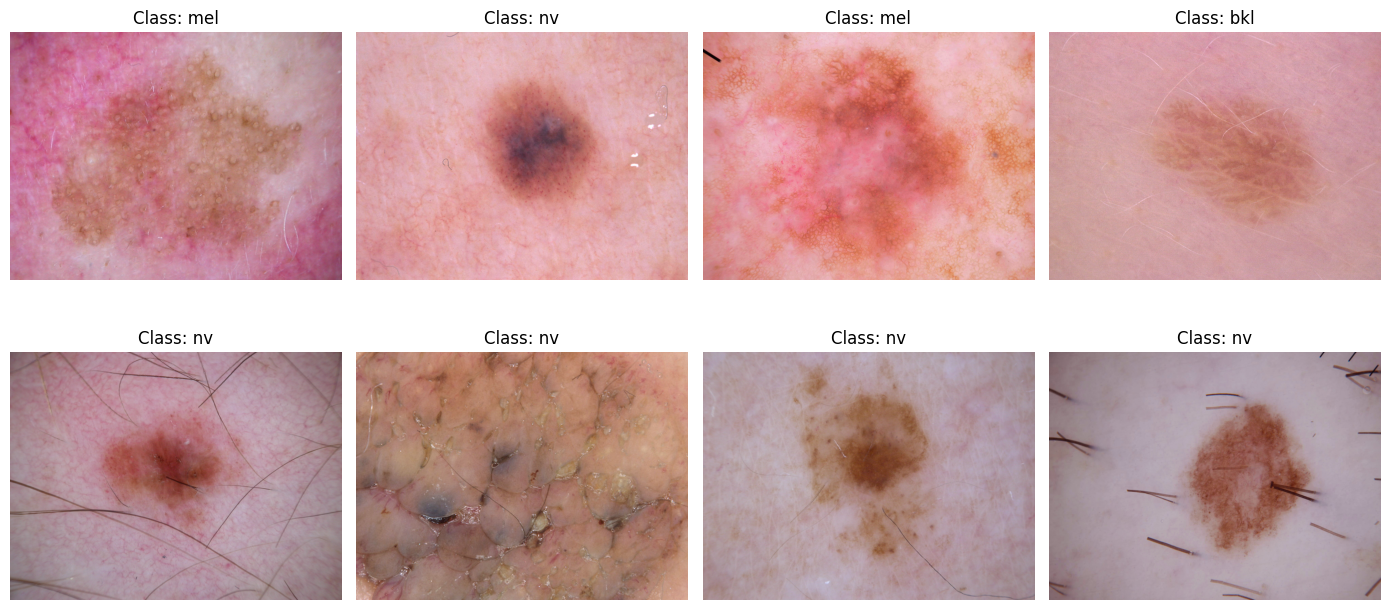

In [9]:
from PIL import Image
import random

# Keep only records with valid image paths
valid_df = df[df["image_path"].notna()].copy()

if len(valid_df) == 0:
    print("No matching images found. Check the image paths.")
else:
    samples = valid_df.sample(
        n=min(8, len(valid_df)),
        random_state=42
    )

    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    axes = axes.flatten()

    for ax, (_, row) in zip(axes, samples.iterrows()):
        image = Image.open(row["image_path"]).convert("RGB")

        ax.imshow(image)
        ax.set_title(f"Class: {row['dx']}")
        ax.axis("off")

    for ax in axes[len(samples):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [10]:
!pip -q install pillow


## 4. Data Preprocessing

Before training the deep learning model, the dataset must be prepared in a consistent format.

The preprocessing stage includes:

- Removing records whose image files are missing.
- Checking image labels and file paths.
- Splitting the data into training, validation, and test sets.
- Resizing images to 224 × 224 pixels.
- Normalizing pixel values using the preprocessing function required by MobileNetV2.

The training set is used to learn model parameters, the validation set is used to monitor model performance during training, and the test set is reserved for final evaluation.


In [11]:
from sklearn.model_selection import train_test_split

# Keep rows with valid image paths and labels
data = df.dropna(subset=["image_path", "dx"]).copy()

# Keep only image paths that exist
data = data[data["image_path"].apply(os.path.isfile)].copy()

# Ensure labels are strings
data["dx"] = data["dx"].astype(str)

print("Valid image records:", len(data))
print("\nClass counts:")
display(data["dx"].value_counts().sort_index().to_frame("Images"))

Valid image records: 10015

Class counts:


,Images
dx,
akiec,327
bcc,514
bkl,1099
df,115
mel,1113
nv,6705
vasc,142



### 4.1 Training, Validation, and Test Sets

We split the dataset into three subsets using stratified sampling to preserve the approximate class distribution in each subset.

- **70% training set:** Used to train the model.
- **15% validation set:** Used to monitor training and select the best model.
- **15% test set:** Used only for final performance evaluation.

The split is performed at the image-record level, with a fixed random seed to make the experiment reproducible.


In [12]:
# First, reserve 15% for testing
train_val_df, test_df = train_test_split(
    data,
    test_size=0.15,
    random_state=42,
    stratify=data["dx"]
)

# From the remaining 85%, reserve enough for 15% of the full dataset
train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.15 / 0.85,
    random_state=42,
    stratify=train_val_df["dx"]
)

print(f"Training images:   {len(train_df)} ({len(train_df)/len(data):.1%})")
print(f"Validation images: {len(val_df)} ({len(val_df)/len(data):.1%})")
print(f"Test images:       {len(test_df)} ({len(test_df)/len(data):.1%})")

Training images:   7009 (70.0%)
Validation images: 1503 (15.0%)
Test images:       1503 (15.0%)


In [13]:
split_counts = pd.DataFrame({
    "Train": train_df["dx"].value_counts(normalize=True),
    "Validation": val_df["dx"].value_counts(normalize=True),
    "Test": test_df["dx"].value_counts(normalize=True)
}).fillna(0).sort_index()

display((split_counts * 100).round(2))

,Train,Validation,Test
dx,,,
akiec,3.27,3.26,3.26
bcc,5.14,5.12,5.12
bkl,10.97,10.98,10.98
df,1.14,1.20,1.13
mel,11.11,11.11,11.11
nv,66.96,66.93,66.93
vasc,1.41,1.40,1.46



## 5. Image Pipeline and Label Encoding

We use TensorFlow's `tf.data` pipeline to load images efficiently during training.

Each image is resized to 224 × 224 pixels. The seven diagnostic labels are encoded as integer class IDs, and MobileNetV2 preprocessing is applied to convert pixel values to the expected input range.

The test set is kept separate from training and validation to reduce the risk of evaluation leakage.


In [14]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

class_names = sorted(data["dx"].unique())
num_classes = len(class_names)

class_to_index = {
    name: index for index, name in enumerate(class_names)
}

print("Classes:", class_names)
print("Number of classes:", num_classes)

Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Number of classes: 7


In [15]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image(image_path, label):
    image_bytes = tf.io.read_file(image_path)
    image = tf.io.decode_jpeg(image_bytes, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = preprocess_input(image)
    return image, label

def make_dataset(frame, training=False):
    paths = frame["image_path"].astype(str).to_numpy()
    labels = frame["dx"].map(class_to_index).to_numpy(dtype="int32")

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            buffer_size=len(frame),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print("Training, validation, and test datasets created.")

Training, validation, and test datasets created.


In [16]:
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Pixel value range:",
          float(tf.reduce_min(images)),
          "to",
          float(tf.reduce_max(images)))

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Pixel value range: -1.0 to 1.0



## 6. Deep Learning Model: MobileNetV2

In this project, we use transfer learning with MobileNetV2, a convolutional neural network pretrained on ImageNet.

The pretrained model is used as a feature extractor, while a new classification head learns to classify images into the seven HAM10000 skin-lesion categories.

The model includes global average pooling, dropout regularization, and a softmax output layer.

The model is developed for educational research and is not intended for clinical diagnosis.


In [17]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow import keras
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, Dropout, Dense
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# Confirm the variables from Step 9 and Step 10 exist
print("Classes:", class_names)
print("Number of classes:", num_classes)

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

inputs = Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
outputs = Dense(num_classes, activation="softmax")(x)

model = Model(inputs, outputs)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Number of classes: 7


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,266,951 (8.65 MB)

 Trainable params: 8,967 (35.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


## 7. Class Imbalance Handling

The HAM10000 dataset contains unequal numbers of images across its seven categories.

To reduce the influence of class imbalance during training, we calculate balanced class weights using only the training labels. These weights assign greater importance to less represented classes.

Class weighting does not guarantee equal performance across classes, so per-class metrics will be examined during evaluation.


In [18]:
from sklearn.utils.class_weight import compute_class_weight

train_labels = train_df["dx"].map(class_to_index).to_numpy()

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(num_classes),
    y=train_labels
)

class_weights = {
    int(i): float(weight)
    for i, weight in enumerate(weights)
}

print("Class weights:")
for i, weight in class_weights.items():
    print(f"{class_names[i]}: {weight:.3f}")

Class weights:
akiec: 4.372
bcc: 2.781
bkl: 1.302
df: 12.516
mel: 1.285
nv: 0.213
vasc: 10.114



## 8. Model Training

The MobileNetV2 classification head is trained using the training dataset, with performance monitored on the validation dataset.

We use early stopping, model checkpointing, and learning-rate reduction to help manage training and retain the best model based on validation loss.

The test dataset is reserved for the final evaluation.


In [19]:
callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        filepath="best_skin_cancer_model.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

In [20]:
EPOCHS = 10

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/10
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 192ms/step - accuracy: 0.3410 - loss: 2.0567
Epoch 1: val_loss improved from None to 1.11958, saving model to best_skin_cancer_model.keras

Epoch 1: finished saving model to best_skin_cancer_model.keras
220/220 ━━━━━━━━━━━━━━━━━━━━ 75s 273ms/step - accuracy: 0.4136 - loss: 1.7125 - val_accuracy: 0.5915 - val_loss: 1.1196 - learning_rate: 0.0010
Epoch 2/10
219/220 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step - accuracy: 0.5601 - loss: 1.2338
Epoch 2: val_loss did not improve from 1.11958
220/220 ━━━━━━━━━━━━━━━━━━━━ 45s 206ms/step - accuracy: 0.5546 - loss: 1.2544 - val_accuracy: 0.5170 - val_loss: 1.2551 - learning_rate: 0.0010
Epoch 3/10
219/220 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step - accuracy: 0.5811 - loss: 1.1384
Epoch 3: val_loss improved from 1.11958 to 0.88520, saving model to best_skin_cancer_model.keras

Epoch 3: finished saving model to best_skin_cancer_model.keras
220/220 ━━━━━━━━━━━━━━━━━━━━ 45s 205ms/step - accuracy: 0.5834 - loss: 1.0986 - va


## 9. Training and Validation Curves

Training and validation accuracy and loss are plotted to understand model learning behavior.

These curves help identify potential overfitting or underfitting. Final model performance will be assessed separately on the held-out test dataset.


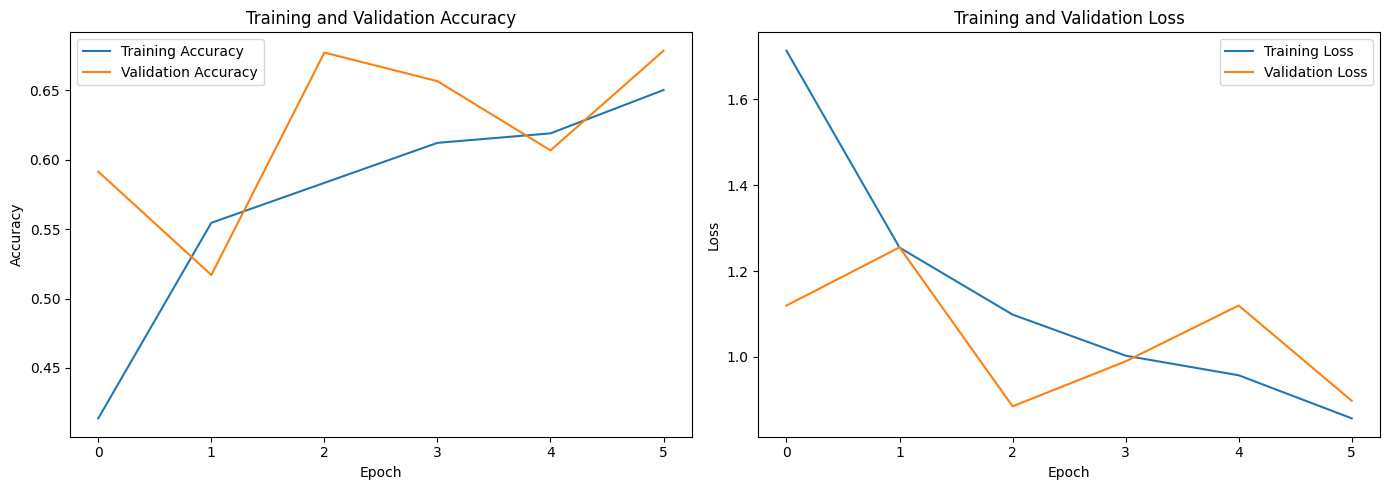

In [21]:
history_df = pd.DataFrame(history.history)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_df["accuracy"], label="Training Accuracy")
axes[0].plot(history_df["val_accuracy"], label="Validation Accuracy")
axes[0].set_title("Training and Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history_df["loss"], label="Training Loss")
axes[1].plot(history_df["val_loss"], label="Validation Loss")
axes[1].set_title("Training and Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.savefig("training_curves.png", dpi=300, bbox_inches="tight")
plt.show()

history_df.to_csv("training_history.csv", index=False)


## 10. Save the Trained Model

The best model checkpoint is saved during training according to validation loss.

We reload this checkpoint and save the final model artifact for later evaluation and reproducibility.


In [22]:
import os

checkpoint_path = "best_skin_cancer_model.keras"

if os.path.exists(checkpoint_path):
    model = keras.models.load_model(checkpoint_path)
    model.save("skin_cancer_mobilenetv2.keras")
    print("Best model loaded and saved successfully.")
else:
    print("Checkpoint not found. Check whether training completed.")

Best model loaded and saved successfully.



## 11. Final Model Evaluation

The trained model is evaluated on the held-out test dataset.

We report test accuracy, macro F1-score, weighted F1-score, and per-class precision, recall, and F1-score. These metrics provide a more complete assessment than accuracy alone, particularly when the dataset is imbalanced.


In [23]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print("Test samples:", len(y_true))
print("Predicted samples:", len(y_pred))

47/47 ━━━━━━━━━━━━━━━━━━━━ 16s 227ms/step
Test samples: 1503
Predicted samples: 1503


In [24]:
test_accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
weighted_f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Macro F1-score: {macro_f1:.4f}")
print(f"Weighted F1-score: {weighted_f1:.4f}")

Test Accuracy: 0.6574
Macro F1-score: 0.4612
Weighted F1-score: 0.6892



### 11.1 Classification Report

The classification report presents precision, recall, F1-score, and sample counts for each lesion category.

Per-class results help identify which categories are more difficult for the model to classify.


In [25]:
report = classification_report(
    y_true,
    y_pred,
    labels=np.arange(num_classes),
    target_names=class_names,
    zero_division=0,
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()

display(report_df.round(4))
report_df.to_csv("classification_report.csv")

,precision,recall,f1-score,support
akiec,0.4390,0.3673,0.4000,49.0000
bcc,0.4426,0.7013,0.5427,77.0000
bkl,0.5116,0.2667,0.3506,165.0000
df,0.0902,0.7059,0.1600,17.0000
mel,0.3429,0.5749,0.4295,167.0000
nv,0.9237,0.7465,0.8257,1006.0000
vasc,0.4643,0.5909,0.5200,22.0000
accuracy,0.6574,0.6574,0.6574,0.6574
macro avg,0.4592,0.5648,0.4612,1503.0000
weighted avg,0.7574,0.6574,0.6892,1503.0000



## 12. Confusion Matrix

The confusion matrix compares actual labels with predicted labels.

Values along the diagonal represent correct predictions, while values outside the diagonal represent classification errors.


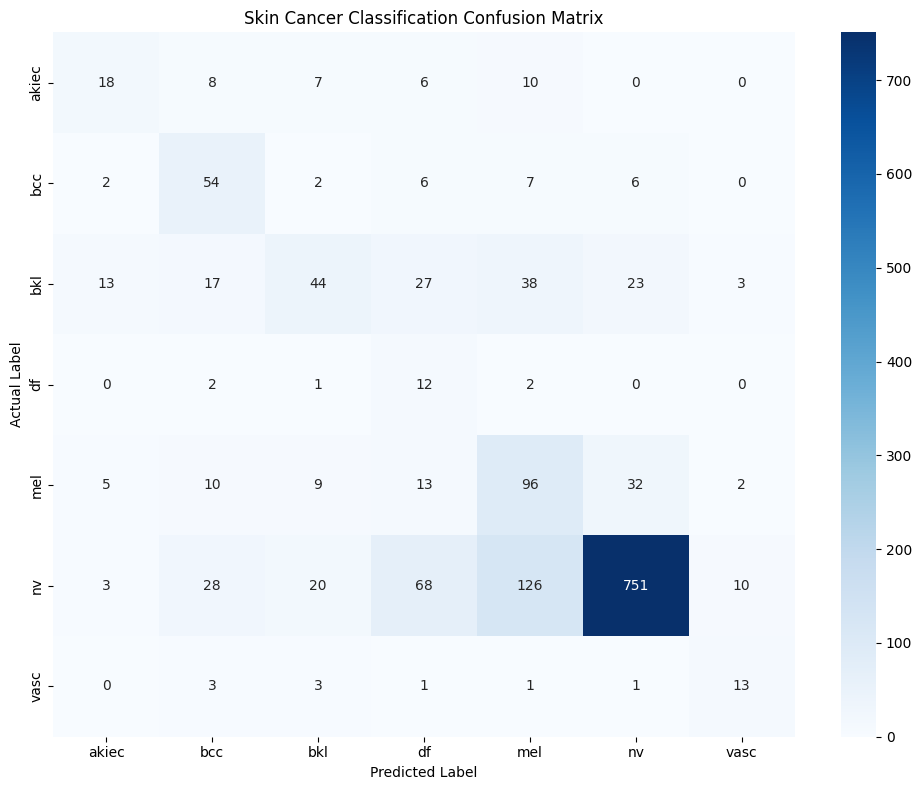

In [26]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Skin Cancer Classification Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()


## 13. Export Evaluation Results

We export the final test metrics to a CSV file so they can be included in the GitHub README and project report.

All values must reflect the actual model evaluation.


In [27]:
metrics_df = pd.DataFrame([{
    "model": "MobileNetV2",
    "num_classes": num_classes,
    "test_samples": len(y_true),
    "test_accuracy": test_accuracy,
    "macro_f1": macro_f1,
    "weighted_f1": weighted_f1
}])

metrics_df.to_csv("evaluation_metrics.csv", index=False)

display(metrics_df.round(4))
print("Evaluation metrics saved.")

,model,num_classes,test_samples,test_accuracy,macro_f1,weighted_f1
0,MobileNetV2,7,1503,0.6574,0.4612,0.6892


Evaluation metrics saved.


---